# Part A

This notebook implements a convolutional neural network for image classification on the CIFAR-10 dataset, following the architecture specified in the coursework.

A key component of the model is a custom Intermediate Block, which combines multiple convolutional branches using learned coefficients derived from channel-wise feature statistics.

The notebook is organised to cover data preprocessing, model construction, training, and evaluation.

### 1. Import and Setup
This section imports the required libraries, configures the notebook to run on the GPU where available and defines the CutMix data augmentation function used during training to improve generalisation.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np
import random
import os
import time

In [ ]:
def cutmix_data(x, y, alpha=1.0):
    batch_size = x.size(0)
    indices = torch.randperm(batch_size).to(x.device)
    shuffled_x = x[indices]
    shuffled_y = y[indices]

    lam = np.random.beta(alpha, alpha)

    W = x.size(2)
    H = x.size(3)
    cut_ratio = np.sqrt(1.0 - lam)
    cut_w = int(W * cut_ratio)
    cut_h = int(H * cut_ratio)

    cx = np.random.randint(W)
    cy = np.random.randint(H)

    bbx1 = np.clip(cx - cut_w // 2, 0, W)
    bby1 = np.clip(cy - cut_h // 2, 0, H)
    bbx2 = np.clip(cx + cut_w // 2, 0, W)
    bby2 = np.clip(cy + cut_h // 2, 0, H)

    x[:, :, bbx1:bbx2, bby1:bby2] = shuffled_x[:, :, bbx1:bbx2, bby1:bby2]

    lam = 1 - ((bbx2 - bbx1) * (bby2 - bby1) / (W * H))

    return x, y, shuffled_y, lam

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

Using device: cuda
GPU name: NVIDIA L4


In [ ]:
seed = 42

torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

print("Random seed set to:", seed)

Random seed set to: 42


### 2. CIFAR-10 Dataset loader
In this part,we'll load the datasets for our classification task

In [ ]:
batch_size = 256

cifar_mean = (0.4914, 0.4822, 0.4465)
cifar_std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(cifar_mean, cifar_std),
    transforms.RandomErasing(p=0.25)

])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(cifar_mean, cifar_std)
])

In [ ]:
import os

data_folder = "./data"

cifar_folder = "./data/cifar-10-batches-py"

os.makedirs(data_folder, exist_ok=True)

if not os.path.exists(cifar_folder):

    print("CIFAR-10 not present, downloading")

    url = "https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz"

    !wget -O ./data/cifar-10-python.tar.gz "$url"

    print("Extracting CIFAR-10")

    !tar -xzf ./data/cifar-10-python.tar.gz -C ./data

    print("CIFAR-10 ready")

else:

    print("CIFAR-10 is already available")

CIFAR-10 is already available


In [ ]:
train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=train_transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=test_transform
)

In [ ]:
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=4,
    pin_memory=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

In [ ]:
print("Number of training images:", len(train_dataset))
print("Number of testing images:", len(test_dataset))
print("Number of training batches:", len(train_loader))
print("Number of testing batches:", len(test_loader))

images, labels = next(iter(train_loader))

print("One batch image shape:", images.shape)
print("One batch label shape:", labels.shape)
print("Minimum label:", labels.min().item())
print("Maximum label:", labels.max().item())

Number of training images: 50000
Number of testing images: 10000
Number of training batches: 196
Number of testing batches: 40
One batch image shape: torch.Size([256, 3, 32, 32])
One batch label shape: torch.Size([256])
Minimum label: 0
Maximum label: 9


### 3. Intermediate Block

In this section, we implement the Intermediate Block from the coursework. It has three parallel convolution paths (1x1, 3x3, and 5x5).

We use global average pooling to get a summary of the input, which is passed through a fully connected layer to produce three weights. These weights are used to scale each path, and the results are added together. Batch normalisation and an activation function are then applied.

In [ ]:
class IntermediateBlock(nn.Module):
    def __init__(self, input_channels, output_channels):
        super().__init__()

        self.conv_1x1 = nn.Conv2d(input_channels, output_channels, kernel_size=1, padding=0, bias=False)
        self.conv_3x3 = nn.Conv2d(input_channels, output_channels, kernel_size=3, padding=1, bias=False)
        self.conv_5x5 = nn.Conv2d(input_channels, output_channels, kernel_size=5, padding=2, bias=False)

        self.global_pool = nn.AdaptiveAvgPool2d(1)

        self.coefficient_layer = nn.Linear(input_channels, 3)

        self.bn = nn.BatchNorm2d(output_channels)
        self.activation = nn.GELU()

    def forward(self, x):
        output_1x1 = self.conv_1x1(x)
        output_3x3 = self.conv_3x3(x)
        output_5x5 = self.conv_5x5(x)

        channel_average = self.global_pool(x)
        channel_average = channel_average.view(channel_average.size(0), -1)

        branch_scores = self.coefficient_layer(channel_average)
        branch_coefficients = branch_scores

        weight_1x1 = branch_coefficients[:, 0].view(-1, 1, 1, 1)
        weight_3x3 = branch_coefficients[:, 1].view(-1, 1, 1, 1)
        weight_5x5 = branch_coefficients[:, 2].view(-1, 1, 1, 1)

        weighted_sum = (
            weight_1x1 * output_1x1 +
            weight_3x3 * output_3x3 +
            weight_5x5 * output_5x5
        )

        final_output = self.activation(self.bn(weighted_sum))

        return final_output

To see if our code is running fine, we'll do a test run in the code below to check that our input is passed correctly and output shape is as expected

In [ ]:
test_block = IntermediateBlock(input_channels=3, output_channels=64).to(device)

test_images = torch.randn(8, 3, 32, 32).to(device)
test_output = test_block(test_images)

print("Input shape:", test_images.shape)
print("Output shape:", test_output.shape)

Input shape: torch.Size([8, 3, 32, 32])
Output shape: torch.Size([8, 64, 32, 32])


### 4.Output Block
The output block takes the final feature map and produces class scores for CIFAR-10 (10 classes).

In [ ]:
class OutputBlock(nn.Module):
    def __init__(self, input_channels, number_of_classes=10):
        super().__init__()

        self.global_pool = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(input_channels, number_of_classes)
        )

    def forward(self, x):
        x = self.global_pool(x)
        x = x.view(x.size(0), -1)
        logits = self.classifier(x)

        return logits

Test run below to see if our code works for output block

In [ ]:
test_output_block = OutputBlock(input_channels=512, number_of_classes=10).to(device)

test_feature_map = torch.randn(8, 512, 4, 4).to(device)
test_logits = test_output_block(test_feature_map)

print("Input feature map shape:", test_feature_map.shape)
print("Output logits shape:", test_logits.shape)

Input feature map shape: torch.Size([8, 512, 4, 4])
Output logits shape: torch.Size([8, 10])


### 5. Full model for CIFAR-10 Classification
In this section, we build the full model by stacking the Intermediate Blocks from the previous section. The number of channels increases at each stage, while max pooling is used to reduce the spatial size between blocks.

The final output block converts the learned features into 10 class scores for CIFAR-10.

In [ ]:
class CIFAR10Model(nn.Module):

    def __init__(self, number_of_classes=10):
        super().__init__()

        self.block1 = IntermediateBlock(input_channels=3, output_channels=64)
        self.block2 = IntermediateBlock(input_channels=64, output_channels=128)
        self.pool1 = nn.MaxPool2d(2)

        self.block3 = IntermediateBlock(input_channels=128, output_channels=256)
        self.pool2 = nn.MaxPool2d(2)

        self.block4 = IntermediateBlock(input_channels=256, output_channels=512)
        self.block5 = IntermediateBlock(input_channels=512, output_channels=512)
        self.pool3 = nn.MaxPool2d(2)



        self.output_block = OutputBlock(
            input_channels=512,
            number_of_classes=number_of_classes
        )

    def forward(self, x):
        x = self.block1(x)      # 64 x 32 x 32
        x = self.block2(x)      # 128 x 32 x 32
        x = self.pool1(x)       # 128 x 16 x 16

        x = self.block3(x)      # 256 x 16 x 16
        x = self.pool2(x)       # 256 x 8 x 8

        x = self.block4(x)      # 512 x 8 x 8
        x = self.block5(x)      # 512 x 8 x 8
        x = self.pool3(x)       # 512 x 4 x 4

        logits = self.output_block(x)

        return logits

Test run of the full model classification

In [ ]:
model = CIFAR10Model().to(device)

test_images = torch.randn(8, 3, 32, 32).to(device)
test_logits = model(test_images)

print("Input shape:", test_images.shape)
print("Output shape:", test_logits.shape)

total_parameters = sum(p.numel() for p in model.parameters())
trainable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)

Input shape: torch.Size([8, 3, 32, 32])
Output shape: torch.Size([8, 10])
Total parameters: 15213858
Trainable parameters: 15213858


### 6. Training function for optimising model weights

In this section, we define the training function for one epoch. The model processes each batch, calculates the loss, and updates its weights using backpropagation.

We also apply CutMix randomly during training to help the model generalise better. The function keeps track of the average loss and training accuracy.

In [ ]:
def train_one_epoch(model, train_loader, loss_function, optimizer, device):
    model.train()

    total_loss = 0
    correct_predictions = 0
    total_images = 0
    batch_losses = []

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        if np.random.rand() < 0.5:
            images, labels_a, labels_b, lam = cutmix_data(images, labels, alpha=1.0)
            outputs = model(images)
            loss = lam * loss_function(outputs, labels_a) + (1 - lam) * loss_function(outputs, labels_b)
        else:
            outputs = model(images)
            loss = loss_function(outputs, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        batch_losses.append(loss.item())
        total_loss += loss.item()

        # Training accuracy is approximate because CutMix mixes images and labels,
        # but predictions are compared only with the original labels.

        predicted_labels = outputs.argmax(dim=1)
        correct_predictions += (predicted_labels == labels).sum().item()
        total_images += labels.size(0)

    average_loss = total_loss / len(train_loader)
    accuracy = 100 * correct_predictions / total_images

    return average_loss, accuracy, batch_losses


### 7. Evaluation Function for Measuring Model Performance

In this section, we define a function to evaluate the model on the test data. The model makes predictions without updating weights, and we compare them with the true labels.

We calculate the average loss and overall accuracy to understand how well the model is performing.

In [ ]:
def evaluate_model(model, data_loader, loss_function, device):
    model.eval()

    total_loss = 0
    correct_predictions = 0
    total_images = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = loss_function(outputs, labels)

            total_loss += loss.item()

            predicted_labels = outputs.argmax(dim=1)
            correct_predictions += (predicted_labels == labels).sum().item()
            total_images += labels.size(0)

    average_loss = total_loss / len(data_loader)
    accuracy = 100 * correct_predictions / total_images

    return average_loss, accuracy



The untrained model gives around 10% accuracy, which is expected since CIFAR-10 has 10 classes and the predictions are random.

The loss is around 2.30, which also makes sense. For a random classifier using cross-entropy, the expected loss is close to ln(10), which is approximately 2.30.

In [ ]:
model = CIFAR10Model().to(device)
loss_function = nn.CrossEntropyLoss(label_smoothing=0.1)

test_loss, test_accuracy = evaluate_model(
    model,
    test_loader,
    loss_function,
    device
)

print("Untrained model test loss:", round(test_loss, 4))
print("Untrained model test accuracy:", round(test_accuracy, 2), "%")

Untrained model test loss: 2.303
Untrained model test accuracy: 10.0 %


### 8. Two-Epoch Test Run

In this section, we run a short two-epoch training test to make sure everything is working correctly. This includes the model, loss function, optimizer, scheduler, and training loop.

In [ ]:
%%time

model = CIFAR10Model().to(device)
loss_function = nn.CrossEntropyLoss(label_smoothing=0.1)
number_of_epochs = 2

optimizer = optim.SGD(
    model.parameters(),
    lr=0.05,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=number_of_epochs
)


all_batch_losses = []
train_accuracies = []
test_accuracies = []
train_losses = []
test_losses = []

for epoch in range(number_of_epochs):
    train_loss, train_accuracy, batch_losses = train_one_epoch(
        model,
        train_loader,
        loss_function,
        optimizer,
        device
    )

    test_loss, test_accuracy = evaluate_model(
        model,
        test_loader,
        loss_function,
        device
    )

    scheduler.step()

    all_batch_losses.extend(batch_losses)
    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accuracies.append(train_accuracy)
    test_accuracies.append(test_accuracy)

    print(
        f"Epoch {epoch + 1}/{number_of_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

Epoch 1/2 | Train Loss: 2.3890 | Train Accuracy: 10.14% | Test Loss: 7571.0582 | Test Accuracy: 9.44%
Epoch 2/2 | Train Loss: 2.3431 | Train Accuracy: 10.16% | Test Loss: 1508.8610 | Test Accuracy: 12.49%
CPU times: user 1min 10s, sys: 798 ms, total: 1min 11s
Wall time: 1min 11s


The two-epoch run was used only as a sanity check to verify that the model, training loop, loss computation, and evaluation pipeline were functioning correctly. Since the model was still in a very early stage of training, these results were not intended to represent converged performance.

In [ ]:
%%time
model = CIFAR10Model().to(device)

loss_function = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = optim.SGD(
    model.parameters(),
    lr=0.05,
    momentum=0.9,
    weight_decay=5e-4
)

number_of_epochs = 200

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=number_of_epochs
)

all_batch_losses = []
train_accuracies = []
test_accuracies = []
train_losses = []
test_losses = []

best_test_accuracy = 0
best_epoch = 0

start_time = time.time()

for epoch in range(number_of_epochs):
    train_loss, train_accuracy, batch_losses = train_one_epoch(
        model,
        train_loader,
        loss_function,
        optimizer,
        device
    )

    test_loss, test_accuracy = evaluate_model(
        model,
        test_loader,
        loss_function,
        device
    )

    scheduler.step()

    all_batch_losses.extend(batch_losses)
    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accuracies.append(train_accuracy)
    test_accuracies.append(test_accuracy)

    if test_accuracy > best_test_accuracy:
        best_test_accuracy = test_accuracy
        best_epoch = epoch + 1
        torch.save(model.state_dict(),"part_a_version3_model.pth")

    print(
        f"Epoch {epoch + 1}/{number_of_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_accuracy:.2f}% | "
        f"Best: {best_test_accuracy:.2f}% at epoch {best_epoch}"
    )

end_time = time.time()

print("=" * 60)
print("Training complete")
print("Best test accuracy:", round(best_test_accuracy, 2), "%")
print("Best epoch:", best_epoch)
print("Total training time:", round((end_time - start_time) / 60, 2), "minutes")
print("=" * 60)

Epoch 1/200 | Train Loss: 2.4260 | Train Accuracy: 10.18% | Test Loss: 48498192.1152 | Test Accuracy: 12.26% | Best: 12.26% at epoch 1
Epoch 2/200 | Train Loss: 2.4039 | Train Accuracy: 10.39% | Test Loss: 594197164.2640 | Test Accuracy: 10.70% | Best: 12.26% at epoch 1
Epoch 3/200 | Train Loss: 2.3690 | Train Accuracy: 10.35% | Test Loss: 487.8452 | Test Accuracy: 11.53% | Best: 12.26% at epoch 1
Epoch 4/200 | Train Loss: 2.3329 | Train Accuracy: 10.32% | Test Loss: 5.9327 | Test Accuracy: 11.19% | Best: 12.26% at epoch 1
Epoch 5/200 | Train Loss: 2.3035 | Train Accuracy: 10.44% | Test Loss: 106.4893 | Test Accuracy: 11.28% | Best: 12.26% at epoch 1
Epoch 6/200 | Train Loss: 2.2982 | Train Accuracy: 10.55% | Test Loss: 29.8789 | Test Accuracy: 11.08% | Best: 12.26% at epoch 1
Epoch 7/200 | Train Loss: 2.2963 | Train Accuracy: 10.68% | Test Loss: 86.3872 | Test Accuracy: 10.82% | Best: 12.26% at epoch 1
Epoch 8/200 | Train Loss: 2.2941 | Train Accuracy: 11.19% | Test Loss: 2.2933 | Tes

As shown in the results, the model achieved a best test accuracy of 93.3% at epoch 190. Training accuracy (around 86-88%) is lower than test accuracy (around 92-93%), which is expected due to strong data augmentation during training.

### 9. Loading the best model and plots



In [ ]:
best_model = CIFAR10Model().to(device)

best_model.load_state_dict(
    torch.load("part_a_version3_model.pth", map_location=device)
)

best_model.eval()

final_test_loss, final_test_accuracy = evaluate_model(
    best_model,
    test_loader,
    loss_function,
    device
)

print("Best model test loss:", round(final_test_loss, 4))
print("Best model test accuracy:", round(final_test_accuracy, 2), "%")

Best model test loss: 0.7046
Best model test accuracy: 93.3 %


#### 9.1 Plot of training loss per batch

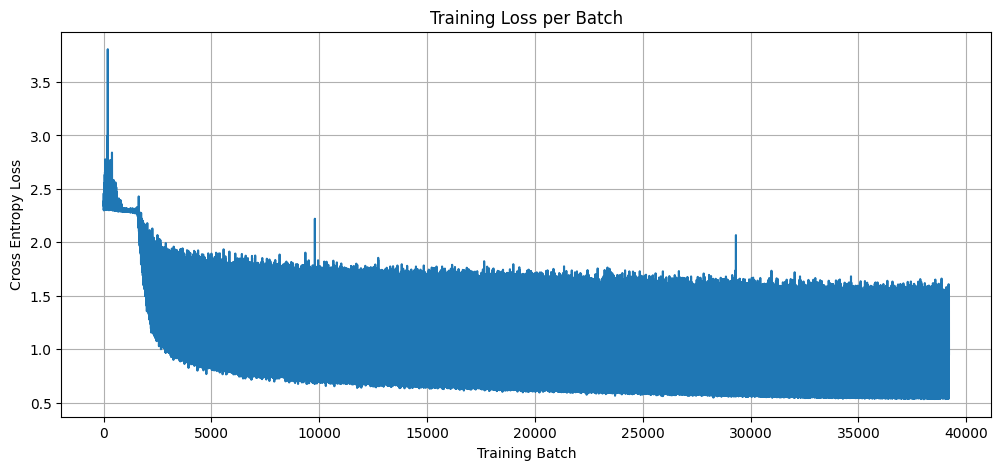

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(all_batch_losses)
plt.xlabel("Training Batch")
plt.ylabel("Cross Entropy Loss")
plt.title("Training Loss per Batch")
plt.grid(True)
plt.savefig('loss_plot.png', dpi=150, bbox_inches='tight')
plt.show()

#### 9.2 Plot of train/test accuracy per epoch

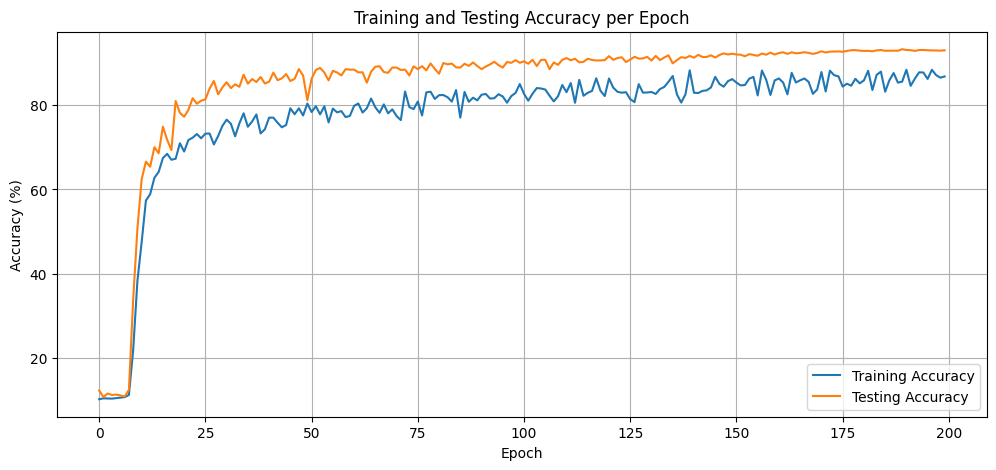

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(test_accuracies, label="Testing Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Testing Accuracy per Epoch")
plt.legend()
plt.grid(True)
plt.savefig('accuracy_plot.png', dpi=150, bbox_inches='tight')
plt.show()

#### 9.3 Plot of Training and Testing Loss per Epoch


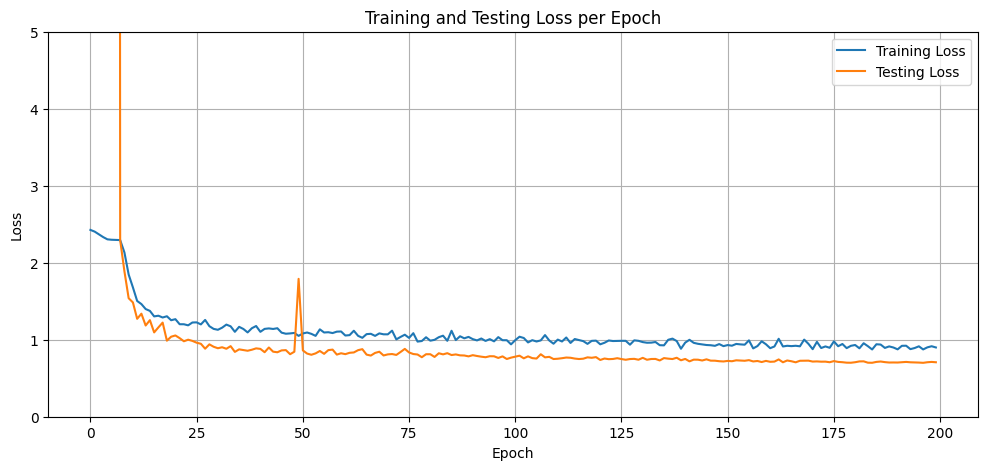

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(test_losses, label="Testing Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Testing Loss per Epoch")
plt.legend()
plt.grid(True)
plt.ylim(0, 5)  # HERE — after plots are defined, before show
plt.savefig('loss_epoch_plot.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
print("Part A Result Summary")
print("=" * 50)
print("Dataset: CIFAR-10")
print("Model: CNN based on the provided intermediate block design")
print("Blocks: 5")
print("Branches per block: 1x1, 3x3, 5x5")
print("Channels: 64 -> 128 -> 256 -> 512 -> 512")
print("Optimizer: SGD")
print("Learning rate: 0.05")
print("Batch size:", batch_size)
print("Epochs:", number_of_epochs)
print("Best test accuracy:", round(best_test_accuracy, 2), "%")
print("Best epoch:", best_epoch)


Part A Result Summary
Dataset: CIFAR-10
Model: CNN based on the provided intermediate block design
Blocks: 5
Branches per block: 1x1, 3x3, 5x5
Channels: 64 -> 128 -> 256 -> 512 -> 512
Optimizer: SGD
Learning rate: 0.05
Batch size: 256
Epochs: 200
Best test accuracy: 93.3 %
Best epoch: 190


The model uses five intermediate blocks. Each block contains three independent convolution branches with 1×1, 3×3, and 5×5 kernels. The input feature map is globally averaged channel-wise and passed through a fully connected layer to generate three coefficients. These coefficients weight the three branch outputs, which are summed and passed through batch normalisation and GELU activation.